In [33]:
import pandas as pd

In [34]:
import numpy as np

In [35]:
import matplotlib.pyplot as plt

In [36]:
import seaborn as sns

In [37]:
from sklearn.model_selection import train_test_split

In [38]:
from sklearn.linear_model import LinearRegression

In [39]:
from sklearn.metrics import mean_squared_error, r2_score

In [40]:
df = pd.read_csv('C:/DS-Complete-studio/data_files/Bike-Sharing-Dataset/day.csv')

In [41]:
df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [43]:
categorical_cols = ['season','weathersit','mnth','weekday']

In [44]:
df = pd.get_dummies(df,columns=categorical_cols,drop_first=True)

In [45]:
df.head()

,instant,dteday,yr,holiday,workingday,temp,atemp,hum,windspeed,casual,...,mnth_9,mnth_10,mnth_11,mnth_12,weekday_1,weekday_2,weekday_3,weekday_4,weekday_5,weekday_6
0,1,2011-01-01,0,0,0,0.344167,0.363625,0.805833,0.160446,331,...,False,False,False,False,False,False,False,False,False,True
1,2,2011-01-02,0,0,0,0.363478,0.353739,0.696087,0.248539,131,...,False,False,False,False,False,False,False,False,False,False
2,3,2011-01-03,0,0,1,0.196364,0.189405,0.437273,0.248309,120,...,False,False,False,False,True,False,False,False,False,False
3,4,2011-01-04,0,0,1,0.200000,0.212122,0.590435,0.160296,108,...,False,False,False,False,False,True,False,False,False,False
4,5,2011-01-05,0,0,1,0.226957,0.229270,0.436957,0.186900,82,...,False,False,False,False,False,False,True,False,False,False


In [46]:
df.columns

Index(['instant', 'dteday', 'yr', 'holiday', 'workingday', 'temp', 'atemp',
       'hum', 'windspeed', 'casual', 'registered', 'cnt', 'season_2',
       'season_3', 'season_4', 'weathersit_2', 'weathersit_3', 'mnth_2',
       'mnth_3', 'mnth_4', 'mnth_5', 'mnth_6', 'mnth_7', 'mnth_8', 'mnth_9',
       'mnth_10', 'mnth_11', 'mnth_12', 'weekday_1', 'weekday_2', 'weekday_3',
       'weekday_4', 'weekday_5', 'weekday_6'],
      dtype='object')

In [47]:
X = df.drop(['instant', 'dteday', 'casual', 'registered', 'cnt'], axis=1)
y = df['cnt']

print(X.shape)
print(y.shape)

(731, 29)
(731,)


In [48]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression()

# 1. The model learns the patterns
model.fit(X_train, y_train)

# 2. The model takes the test
y_pred = model.predict(X_test)

# 3. We grade the test
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared: {r2:.4f}")

Mean Squared Error: 634351.36
R-squared: 0.8418


In [49]:
print(df.isnull().sum())

instant         0
dteday          0
yr              0
holiday         0
workingday      0
temp            0
atemp           0
hum             0
windspeed       0
casual          0
registered      0
cnt             0
season_2        0
season_3        0
season_4        0
weathersit_2    0
weathersit_3    0
mnth_2          0
mnth_3          0
mnth_4          0
mnth_5          0
mnth_6          0
mnth_7          0
mnth_8          0
mnth_9          0
mnth_10         0
mnth_11         0
mnth_12         0
weekday_1       0
weekday_2       0
weekday_3       0
weekday_4       0
weekday_5       0
weekday_6       0
dtype: int64


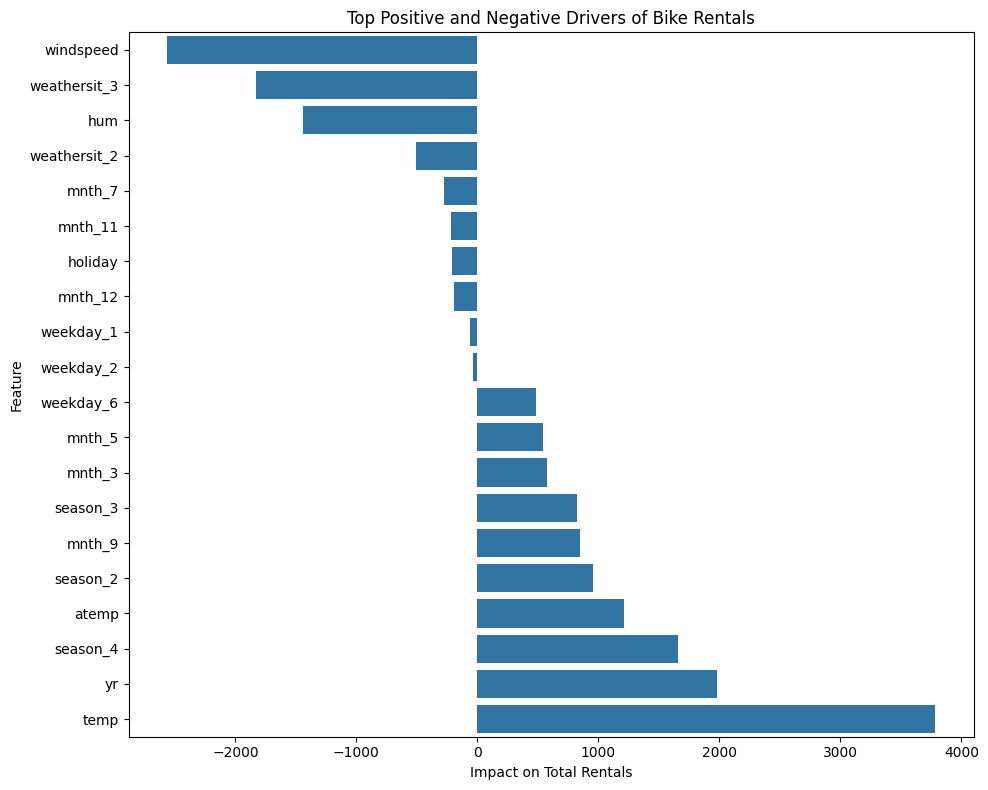

         Feature       Weight
6      windspeed -2565.287684
11  weathersit_3 -1826.372063
5            hum -1441.696058
10  weathersit_2  -508.438725
17        mnth_7  -274.881371
    Feature       Weight
7  season_2   951.858211
4     atemp  1210.089874
9  season_4  1654.242956
0        yr  1981.834582
3      temp  3783.399636


In [50]:
coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Weight': model.coef_
})

coefficients = coefficients.sort_values(by='Weight')

plt.figure(figsize=(10, 8))
sns.barplot(x='Weight', y='Feature', data=pd.concat([coefficients.head(10), coefficients.tail(10)]))
plt.title('Top Positive and Negative Drivers of Bike Rentals')
plt.xlabel('Impact on Total Rentals')
plt.tight_layout()
plt.show()

print(coefficients.head())
print(coefficients.tail())

In [52]:
# Drop atemp to remove the multicollinearity noise
X_clean = X_train.drop('atemp', axis=1)
X_test_clean = X_test.drop('atemp', axis=1)

# Retrain the model on the clean data
model_clean = LinearRegression()
model_clean.fit(X_clean, y_train)

# Check the new R-squared
y_pred_clean = model_clean.predict(X_test_clean)
print(f"Cleaned R-squared: {r2_score(y_test, y_pred_clean):.4f}")

# Look at how the temp coefficient stabilized
clean_coefs = pd.DataFrame({
    'Feature': X_clean.columns,
    'Weight': model_clean.coef_
}).sort_values(by='Weight', ascending=False)

print("\nNew Top Positive Weights:")
print(clean_coefs.head(5))

Cleaned R-squared: 0.8411

New Top Positive Weights:
     Feature       Weight
3       temp  4886.030212
0         yr  1980.059449
8   season_4  1654.881427
6   season_2   955.968013
18    mnth_9   837.030972


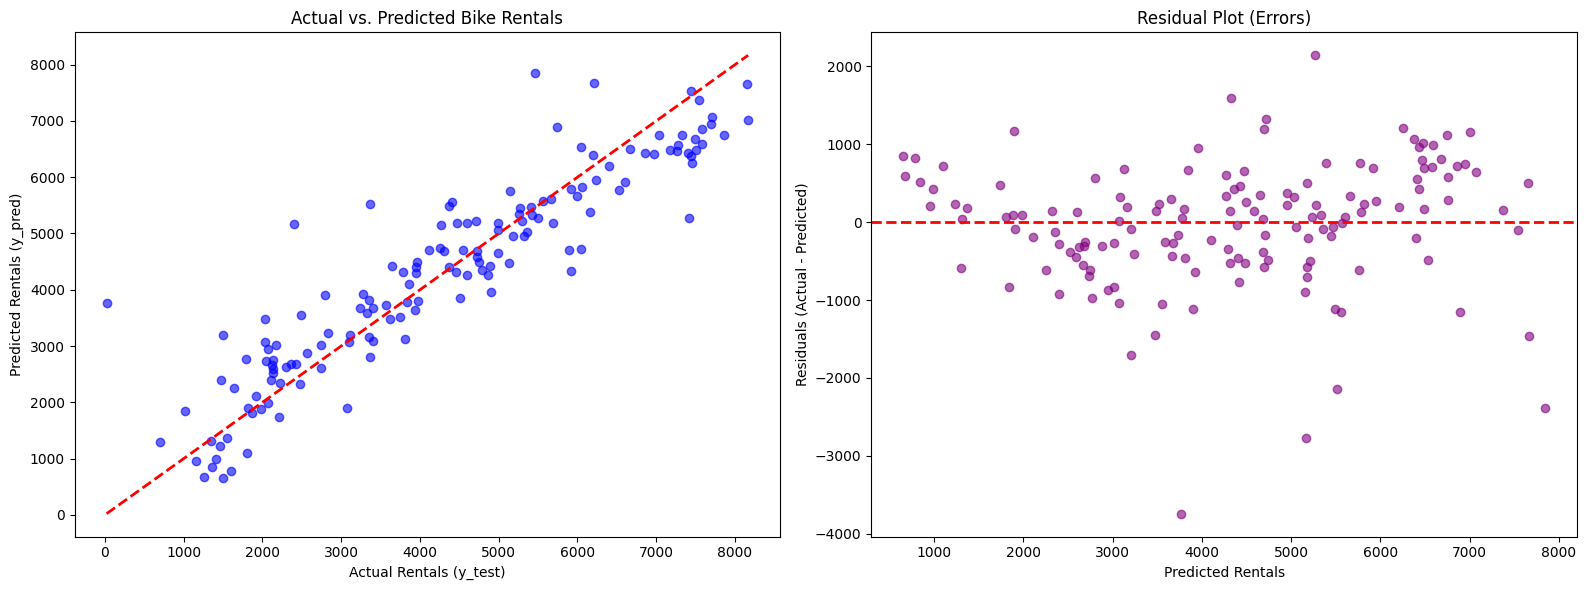

In [ ]:
# Calculate the residuals (the errors)
residuals = y_test - y_pred_clean

# Set up a figure with 2 subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].scatter(y_test, y_pred_clean, alpha=0.6, color='blue')

# Draw the perfect prediction line (y = x)
# We use the minimum and maximum actual values to set the line's start and end points
min_val = min(y_test.min(), y_pred_clean.min())
max_val = max(y_test.max(), y_pred_clean.max())
axes[0].plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2)

axes[0].set_title('Actual vs. Predicted Bike Rentals')
axes[0].set_xlabel('Actual Rentals (y_test)')
axes[0].set_ylabel('Predicted Rentals (y_pred)')

axes[1].scatter(y_pred_clean, residuals, alpha=0.6, color='purple')

# Draw a horizontal line at 0 (representing zero error)
axes[1].axhline(y=0, color='red', linestyle='--', linewidth=2)

axes[1].set_title('Residual Plot (Errors)')
axes[1].set_xlabel('Predicted Rentals')
axes[1].set_ylabel('Residuals (Actual - Predicted)')

plt.tight_layout()
plt.show()